# Simulate a geological source and compute its potential field components

### Things we have to import

In [1]:
# Run this cell to create and save the model.
# Set this cel as 'Raw' if you want load a predefined model.

# PyVista is a helper library for the Visualization Toolkit (VTK) that takes 
# a different approach on interfacing with VTK through NumPy and direct array access.
# https://docs.pyvista.org/version/stable/
import pyvista as pv

# Python package noise (https://github.com/caseman/noise) for generating Perlin noise.
# Such noise is usefull to simulate topography.
import noise

In [2]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import imshow
from PIL import Image

In [3]:
import pickle

In [4]:
import numpy as np
from gravmag import data_structures, utils
from gravmag.models import rectangular_prism as rp
from gravmag import plot_functions as plf

In [5]:
import time

### Set the model area and number of prisms along the horizontal directions

In [6]:
# number of prisms forming the model along the x and y directions
model_shape = (40, 50)

# minimum x, maximum x, minimum y and maximum y
model_area = [-5100, 4900, -3800, 6200]

In [7]:
model_dx, model_dy = data_structures.grid_xy_spacing(area=model_area, shape=model_shape)
print('model dx = {:.3f} m | model dy = {:.3f} m'.format(model_dx, model_dy))

model dx = 256.410 m | model dy = 204.082 m


### Define a reference surface on which the model will be attached

In [8]:
# horizontal boundaries of the prisms
X, Y = data_structures.grid_xy_to_full_matrices_view(
    x = np.linspace(
        model_area[0] + 0.5*model_dx, 
        model_area[1] - 0.5*model_dx, 
        model_shape[0]
    ),
    y = np.linspace(
        model_area[2] + 0.5*model_dy, 
        model_area[3] - 0.5*model_dy, 
        model_shape[1]
    ),
    shape = model_shape
)

In [9]:
# reference point
xc = 0.5*(model_area[0]+model_area[1])
yc = 0.5*(model_area[2]+model_area[3])

# polynomial function defining the reference surface
reference_surface = 300.

### Define/Load the thickness of all rectangular cells covering the simulated area

In [10]:
# Generate a synthetic random surfaces with the Python package [`noise`](https://pypi.org/project/noise/),
# by following the example presented at [Jack McKew's Blog](https://jackmckew.dev/3d-terrain-in-python.html)

# parameters controlling the surface
amplitude = 600.

# generate the surface
thickness = np.zeros(model_shape)
for i in range(model_shape[0]):
    for j in range(model_shape[1]):
        thickness[i][j] = noise.pnoise2(
            i/25, 
            j/15, 
            octaves=2, 
            persistence=0.2,
            lacunarity=6, 
            repeatx=2, 
            repeaty=2, 
            base=0
        )
thickness = (
    amplitude*(
        (thickness - np.min(thickness))/(np.max(thickness) - np.min(thickness))
    )
)

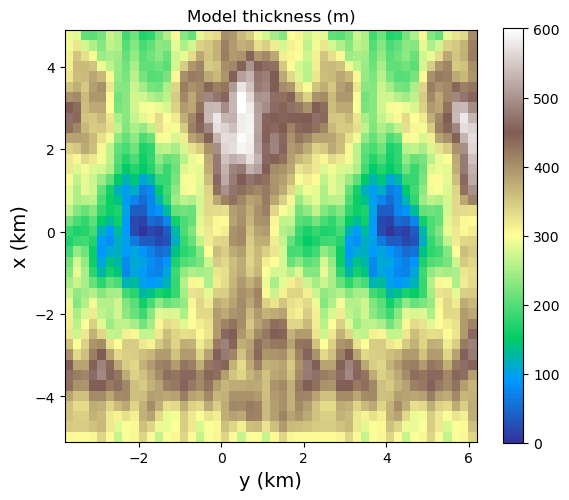

In [11]:
plt.close('all')
plt.figure(figsize=(6,5))

plt.title("Model thickness (m)")
plt.axis('scaled')
plt.pcolor(
    Y*0.001, X*0.001, thickness, cmap='terrain')
plt.colorbar()
#plf.model_boundaries(model)
plt.ylim(0.001*model_area[0], 0.001*model_area[1])
plt.xlim(0.001*model_area[2], 0.001*model_area[3])
plt.xlabel('y (km)', fontsize=14)
plt.ylabel('x (km)', fontsize=14)

plt.tight_layout()

plt.show()

### Pick/Load points forming the horizontal model boundary

In [12]:
# Run this cell to create and save the model.
# Set this cel as 'Raw' if you want load a predefined model.

boundary_points = pickle.load(open('model_boundary_points.pickle', 'rb'))

### Filter/Load the cells inside the boundary

In [13]:
# Run this cell to create and save the model.
# Set this cel as 'Raw' if you want load a predefined model.

model = pickle.load(open('model/model.pickle', 'rb'))

In [14]:
# Run this cell to create and save the model.
# Set this cel as 'Raw' if you want load a predefined model.

mag_intensity = pickle.load(open('model/model_mag_intensity.pickle', 'rb'))
mag_inc = pickle.load(open('model/model_mag_inc.pickle', 'rb'))
mag_dec = pickle.load(open('model/model_mag_dec.pickle', 'rb'))

In [15]:
# compute the Cartesian components of magnetization
mx, my, mz = utils.magnetization_components(
    np.vstack([mag_intensity, mag_inc, mag_dec]).T
)

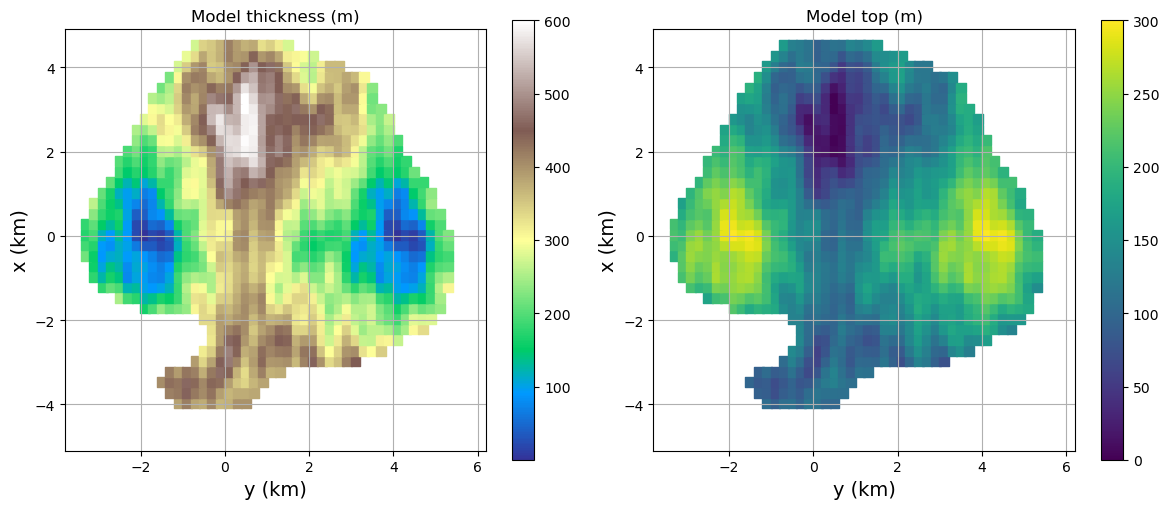

In [16]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.title("Model thickness (m)")
plt.axis('scaled')
plt.scatter(
    x=0.5*(model['y1']+model['y2'])*0.001, 
    y=0.5*(model['x1']+model['x2'])*0.001, 
    s=50,
    c=model['z2']-model['z1'],
    marker='s',
    cmap='terrain'
)
plt.colorbar()
plt.ylim(0.001*model_area[0], 0.001*model_area[1])
plt.xlim(0.001*model_area[2], 0.001*model_area[3])
plt.xlabel('y (km)', fontsize=14)
plt.ylabel('x (km)', fontsize=14)
plt.grid()

plt.subplot(1,2,2)
plt.title("Model top (m)")
plt.axis('scaled')
plt.scatter(
    x=0.5*(model['y1']+model['y2'])*0.001, 
    y=0.5*(model['x1']+model['x2'])*0.001,  
    s=50,
    c=model['z1'],
    marker='s',
    cmap='viridis'
)
plt.colorbar()
plt.ylim(0.001*model_area[0], 0.001*model_area[1])
plt.xlim(0.001*model_area[2], 0.001*model_area[3])
plt.xlabel('y (km)', fontsize=14)
plt.ylabel('x (km)', fontsize=14)
plt.grid()

plt.tight_layout()

plt.show()

### 3D Plot and/or save the model

Execute the following command at the directory `model/`:

# plot image generated with PyVista
<img src='model/model.gif' width='750' align='center'>

Execute the following command at the directory `model/`:

# plot image generated with PyVista
<img src='model/model_slice_y.gif' width='750' align='center'>

### Points were we compute the synthetic data

In [18]:
# Run this cell to create and save the model.
# Set this cel as 'Raw' if you want load a predefined model.

coordinates_grid = pickle.load(open('model/coordinates_grid.pickle', 'rb'))

In [19]:
print('num. data points = {}'.format(coordinates_grid['shape'][0]*coordinates_grid['shape'][1]))

num. data points = 99000


In [20]:
# coordinates rearranged for plotting
# they are "views' of the original coordinates in 'coordinates_grid'
X, Y = data_structures.grid_xy_to_full_matrices_view(
    x = coordinates_grid['x'],
    y = coordinates_grid['y'],
    shape = coordinates_grid['shape']
)

### Main field

In [21]:
# inclination (degrees)
I0 = -30

# declination (degrees)
D0 = -19

# Cartesian components of the main field
Fx_hat, Fy_hat, Fz_hat = utils.unit_vector(inc=I0, dec=D0)

### Synthetic magnetic data

In [22]:
V = pickle.load(open('model/magnetic_potential.pickle', 'rb'))

In [23]:
bx = pickle.load(open('model/magnetic_field_component_bx.pickle', 'rb'))
by = pickle.load(open('model/magnetic_field_component_by.pickle', 'rb'))
bz = pickle.load(open('model/magnetic_field_component_bz.pickle', 'rb'))

In [24]:
b_amp = np.sqrt(bx**2 + by**2 + bz**2)

# Compute the approximated total-field anomaly (Blakely, 1996, p. 179)
approx_tfa = Fx_hat*bx + Fy_hat*by + Fz_hat*bz

In [27]:
rtp = pickle.load(open('model/rtp.pickle', 'rb'))

### Plot the data

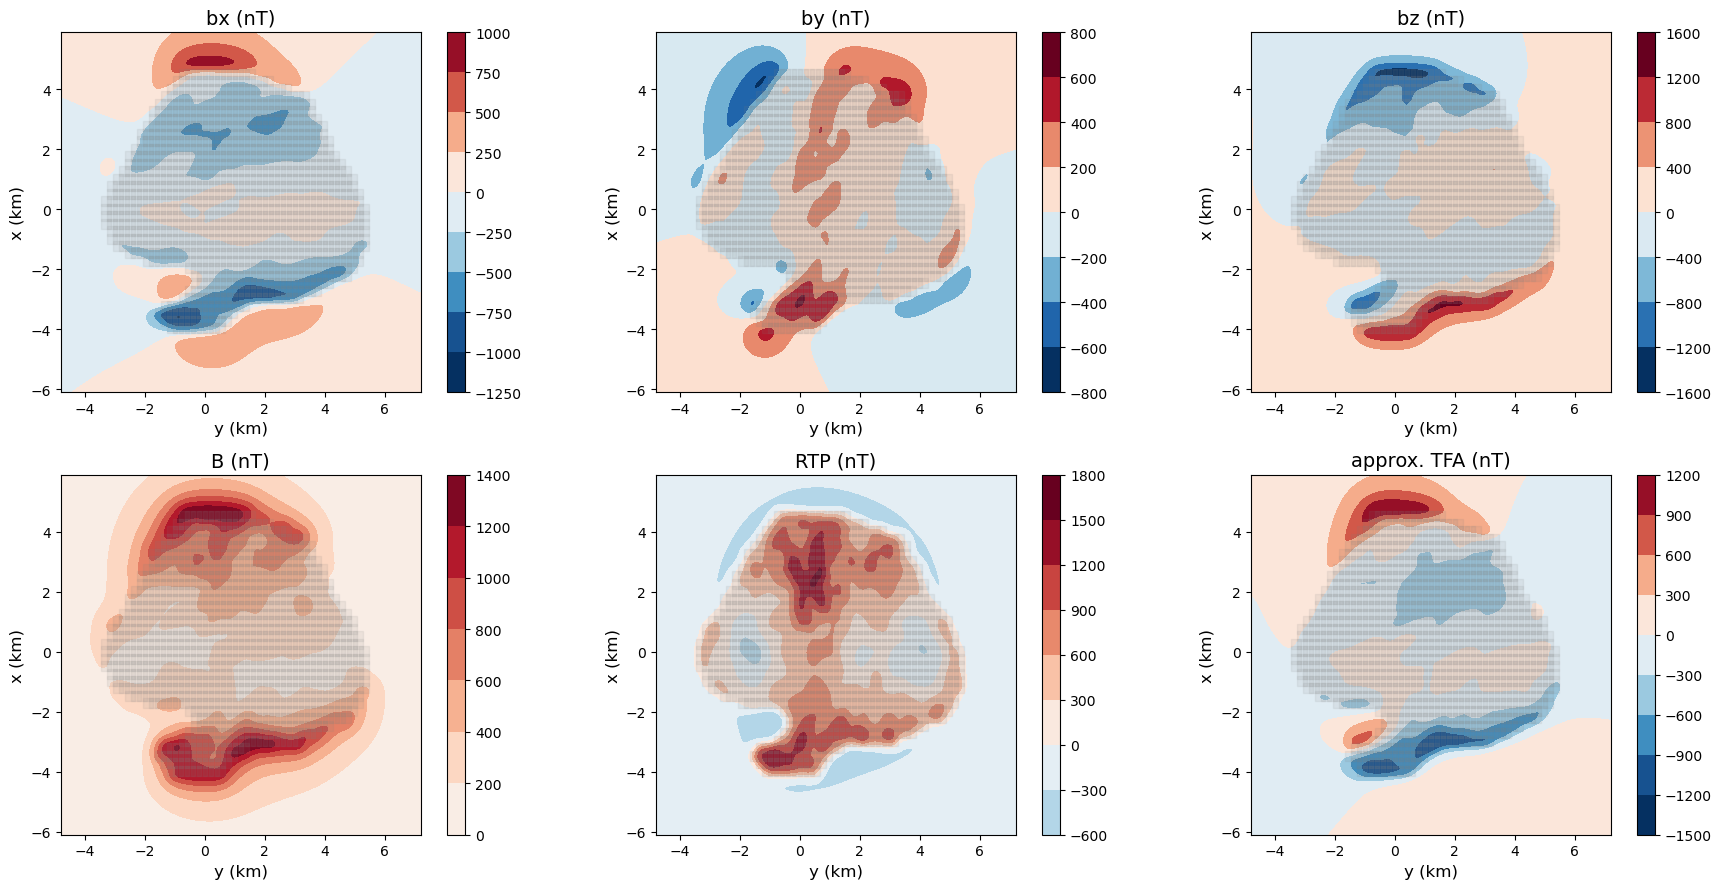

In [28]:
fields = [bx, by, bz, b_amp, rtp, approx_tfa]
windows = [1, 2, 3, 4, 5, 6]
titles = ['bx (nT)', 'by (nT)', 'bz (nT)', 
          'B (nT)', 'RTP (nT)', 'approx. TFA (nT)']

plt.figure(figsize=(18,9))

for w, window in enumerate(windows):
    bounds = np.max(np.abs(fields[w]))
    plt.subplot(2,3,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        Y*0.001, X*0.001, 
        data_structures.grid_xy_full_flatten_to_matrix(
            data=fields[w], ordering='xy', shape=coordinates_grid['shape']
        ), 
        cmap='RdBu_r', vmin=-bounds, vmax=bounds)
    plt.colorbar()

    # horizontal projection of the model
    plt.scatter(
        x=0.5*(model['y1']+model['y2'])*0.001, 
        y=0.5*(model['x1']+model['x2'])*0.001,  
        s=50,
        c='gray',
        marker='s',
        alpha=0.1
    )
    
    plt.ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
    plt.xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
    plt.ylabel('x (km)', fontsize=12)
    plt.xlabel('y (km)', fontsize=12)

plt.tight_layout()

plt.show()